# Figure 6 — KLIFS consensus resistance sites

Reads only `data/processed/` and `data/reference/`. Nothing here recomputes a
screen statistic; if a number looks wrong the fix belongs upstream.

| panel | content | from | status |
|---|---|---|---|
| (whole) | Consensus sites and homologous clinical resistance | `resistance-patterns pipeline (core7)` | **figure** |

**figure** — this notebook regenerates both the source data and the panel.
**source data** — the table regenerates and is checked by `tests/`; the
plotting is still in the original notebook named above.
**not ported** — the plotting is not in this repository yet.
See `docs/COVERAGE.md` for the status of every panel.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(next(p for p in Path.cwd().resolve().parents
                            if (p / "src" / "cdkbe").is_dir()) / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cdkbe import paths, io, editing, lfc, plotting
from cdkbe.source_data import PANELS

plotting.use_style()
paths.ensure(paths.FIG_MAIN)

## Source data

The frames these panels plot.

In [2]:
for key in ["6"]:
    result = PANELS[key]()
    frames = result if isinstance(result, dict) else {"": result}
    for name, df in frames.items():
        label = f"{key}/{name}" if name else key
        print(f"{label:<28} {len(df):>8,} rows x {len(df.columns)} cols")

6                                  33 rows x 8 cols


## Panels

Each panel below is drawn from `data/processed/` and rendered inline, and also
written to `figures/main/`. The numbers printed on the in vivo panels are
checked against the manuscript in `tests/test_invivo_figures.py`.

In [3]:
from matplotlib.figure import Figure

from cdkbe.source_data import DRAWN
from cdkbe.source_data import invivo_figures as ivf

# Drawing functions predate this notebook and return four different shapes: a
# bare figure, (figure, source rows), a dict of either keyed by gene or by
# sub-panel, or -- for the in vivo cohorts -- a list of (figure, stats) pairs.
# `show` takes them all rather than each cell knowing which it is getting.
DRAW = {k: ("invivo" if k in ivf.FIGURES else "screen", v)
        for k, v in DRAWN.items()}


def show(fig, note=None):
    if note:
        print(note)
    display(fig)
    plt.close(fig)


def describe(obj):
    if isinstance(obj, dict):
        return ", ".join(f"{e}: {len(g):,} guides" for e, g in obj.items())
    return f"{len(obj):,} rows"


def draw(key):
    """Draw one panel, show it, and report what it is made of."""
    kind, fn = DRAW[key]
    result = fn(outdir=paths.FIG_MAIN)
    if kind == "invivo":
        for fig, stats in result:
            cols = [c for c in ["Cohort", "comparison", "group",
                                "n_WT", "n_mutant", "p_shown"] if c in stats.columns]
            display(stats[cols])
            show(fig)
        return
    if isinstance(result, Figure):
        show(result)
        return
    if isinstance(result, dict):              # one figure per gene or sub-panel
        for name, v in result.items():
            if isinstance(v, Figure):
                show(v, f"{key} {name}")
            else:
                fig, sub = v
                show(fig, f"{key} {name}: {describe(sub)}")
        return
    fig, obj = result
    if not isinstance(fig, Figure):           # a ChimeraX panel: rendered images
        print(describe(obj))
        display(fig)                          # tiled preview; see structures.Renders
        return
    show(fig, describe(obj))

### 6 — Consensus sites and homologous clinical resistance

33 rows


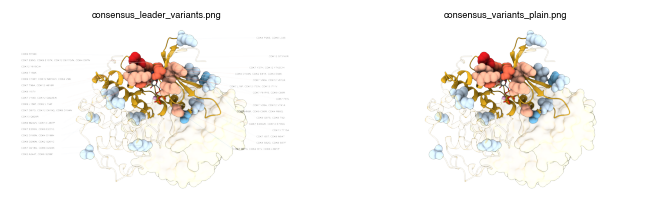

In [4]:
draw("6")